# Calorie Burn Prediction

Machine Learning & Data Analysis Project

Developed by Yair Man

## Research Question

Can the amount of calories burned during a workout be classified based on a person's characteristics and exercise data?

## Dataset

Source: [Gym Members Exercise Dataset](https://www.kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset)

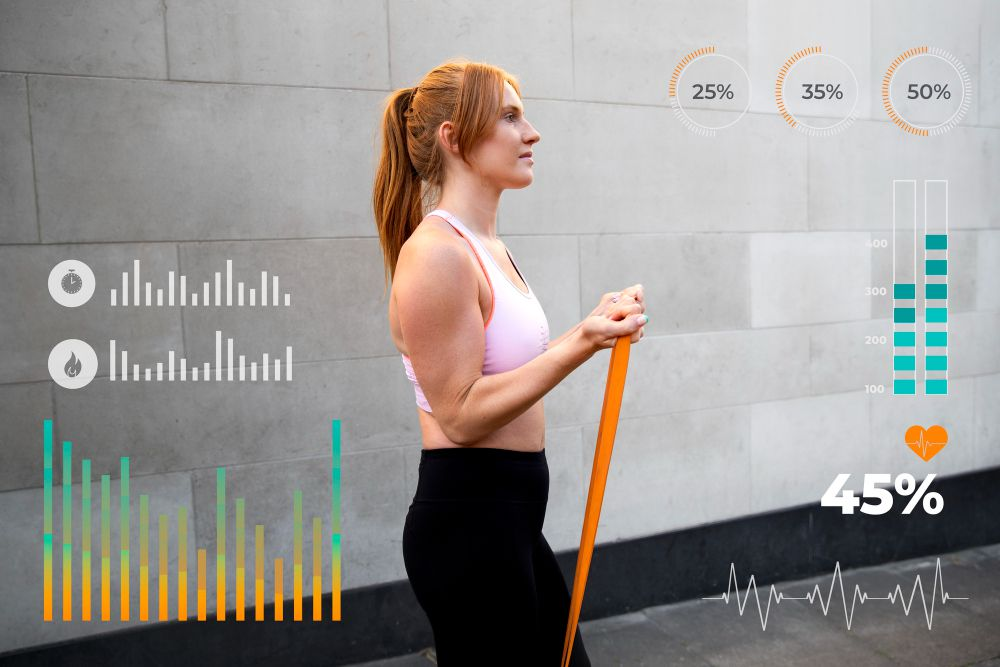

**:הסבר על העמודות**

**Age**: גיל של המתאמנים

**Gender:** המין של המתאמנים

**Weight (kg):** המשקל של המתאמנים

**Height (m):** הגובה של המתאמנים

**Max_BPM:** קצב הלב הגבוה ביותר במהלך האימון

**Avg_BPM:** ממוצע קצב הלב במהלך האימון

**Resting_BPM:** קצב הלב במנוחה לפני האימון

**Session_Duration:** זמן האימון

**Calories_Burned:** כמות הקלוריות שנשרפו

**Workout_Type:** (e.g., Cardio, Strength, Yoga, HIIT) סוג האימון

**Fat_Percentage:** אחוזי השומן בגוף המתאמן

**Water_Intake:** כמות המים ששתה המתאמן בזמן האימון

**Workout_Frequency:** כמות האימונים בשבוע שהמתאמן מבצע

**Experience_Level:** כמות הניסיון: מתחיל (1) מתקדם (2) מקצוען (3)

**BMI:** חישוב מסת גוף (תלוי בגובה ומשקל)

**עמודות שיתווספו**

**Gender:** העמודה תשתנה כך שגבר יופיע במספר 0 ואישה תופיע במספר 1

**Workout_Type_Yoga:** מתי סוג האימון הוא יוגה (1) כשכן (0) כשלא

**Workout_Type_HIIT:** מתי סוג האימון הוא אינטרוולים (1) כשכן (0) כשלא

**Workout_Type_Cardio:** מתי סוג האימון הוא אירובי (1) כשכן (0) כשלא

**Workout_Type_Strength:** מתי סוג האימון הוא אימון כוח (1) כשכן (0) כשלא

**לצורך שאלת המחקר שלי Calories_Burned אני אשתמש בעמודה**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from PIL import Image
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.utils import to_categorical


In [4]:
import pandas as pd

df = pd.read_csv("data/gym_members_exercise_tracking.csv")
df.head()

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


# **גרפים**

משתנה רציף ובדיד

Text(0.5, 1.0, 'Number of calories burned in relation to the session duration')

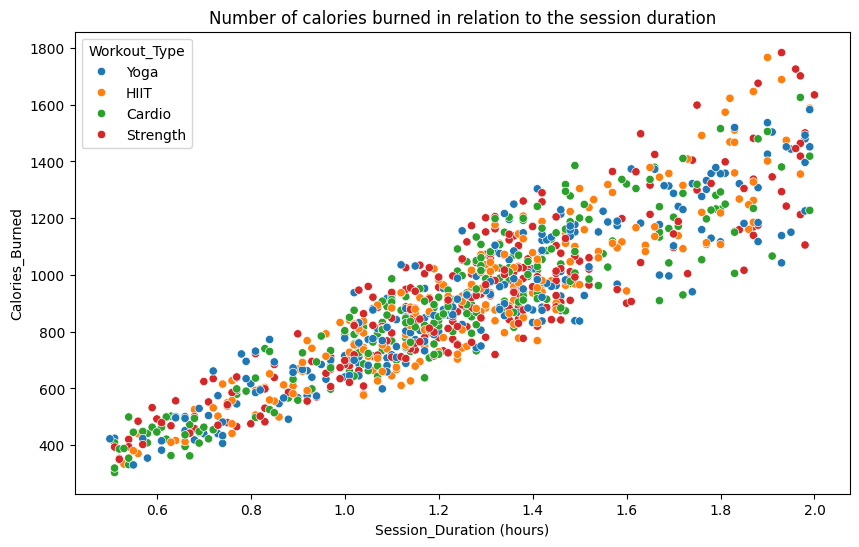

In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Session_Duration (hours)', y='Calories_Burned', data=df ,hue = 'Workout_Type')
plt.title('Number of calories burned in relation to the session duration')

**אנחנו לומדים מהגרף שככל שהאימון יותר ארוך גם שריפת הקלוריות היא גדולה יותר**

משתנה בדיד ורציף

Text(0.5, 1.0, 'Calories Burned in relation to Experience Level')

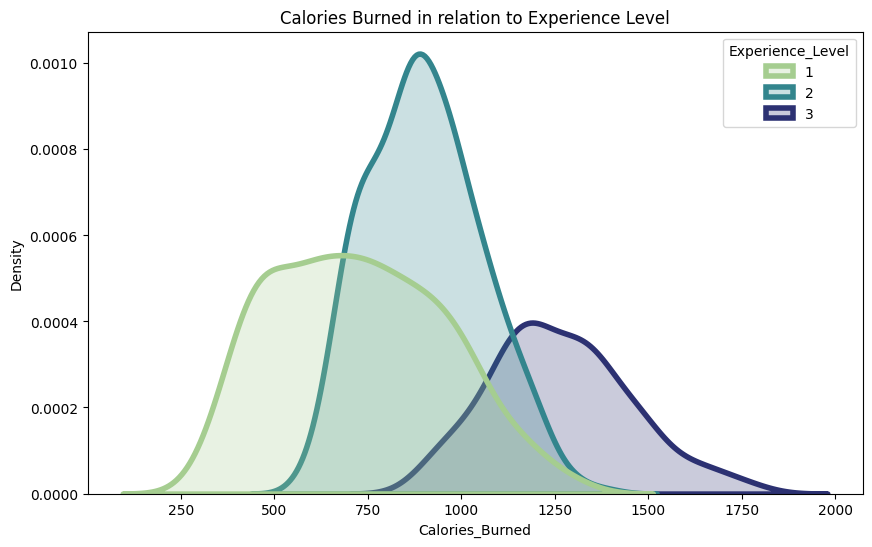

In [6]:
plt.figure(figsize=(10, 6))
sns.kdeplot(hue='Experience_Level', x='Calories_Burned',fill = True , data=df,palette='crest' , linewidth= 4)
plt.title('Calories Burned in relation to Experience Level')

**המסקנה היא שכלל שמתאמן מיומן יותר ככה גם כמות הקלוריות שהוא שורף גדולה יותר בממוצע**

ניתן לראות שרוב המתאמנים המתחילים שורפים בין 400-900 קלוריות

ניתן לראות שרוב המתאמנים המתקדמים שורפים בין 750-1100 קלוריות

ניתן לראות שרוב המתאמנים המקצוענים שורפים בין 1100-1400 קלוריות

משתנה בדיד

/tmp/ipykernel_1383/4006114269.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Workout_Frequency (days/week)', y='Calories_Burned', data=df, palette='cubehelix')


Text(0.5, 1.0, 'Calories Burned in relation to Workout Frequency')

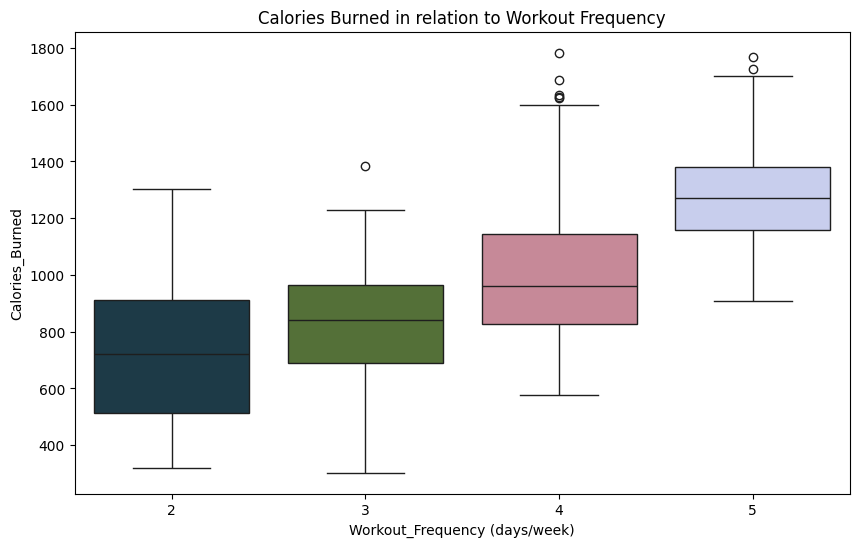

In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Workout_Frequency (days/week)', y='Calories_Burned', data=df, palette='cubehelix')
plt.title('Calories Burned in relation to Workout Frequency')

**ניתן לראות שככל שהמתאמן עושה יותר אימונים בשבוע ככה גם כמות הקלוריות שהוא שורף בכל אימון גדולה יותר**

שני אימונים בשבוע ישרפו בין 550-900 קלוריות

שלושה אימונים בשבוע ישרפו המתאמנים בין 700-980

ארבע אימונים שבוע יגרמו ל900-1100 קלוריות שרופות

וחמישה אימונים בשבוע יגרמו למתאמן לשרוף בין 1200-1400 קלוריות

משתנה בדיד

/tmp/ipykernel_1383/1134386844.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Gender', y='Calories_Burned', data=df, palette='viridis')


Text(0.5, 1.0, 'Gender impact on calories burned')

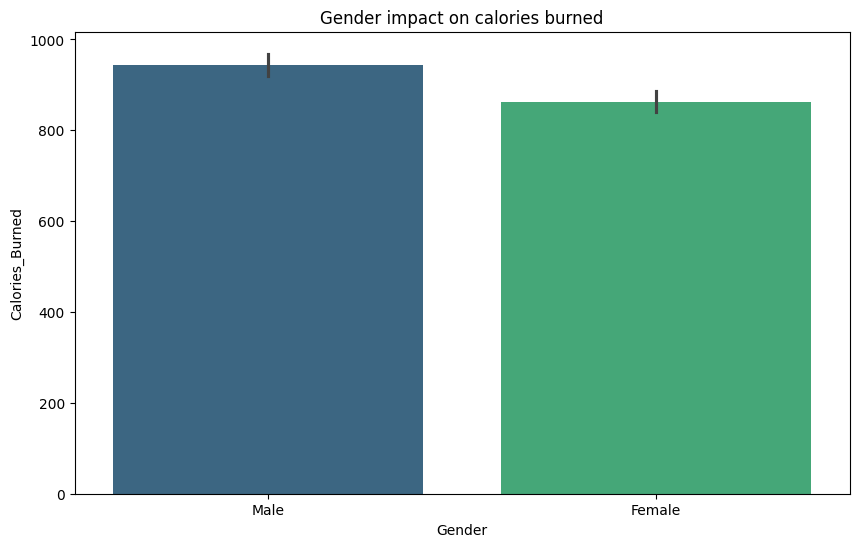

In [8]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Gender', y='Calories_Burned', data=df, palette='viridis')
plt.title('Gender impact on calories burned')

**לפי איך ששינינו בהינדוס נתונים כאשר 0=גבר 1=אישה ניתן לראות שגברים שורפים יותר קלוריות מגברים**

משתנה רציף ומשתנה בדיד


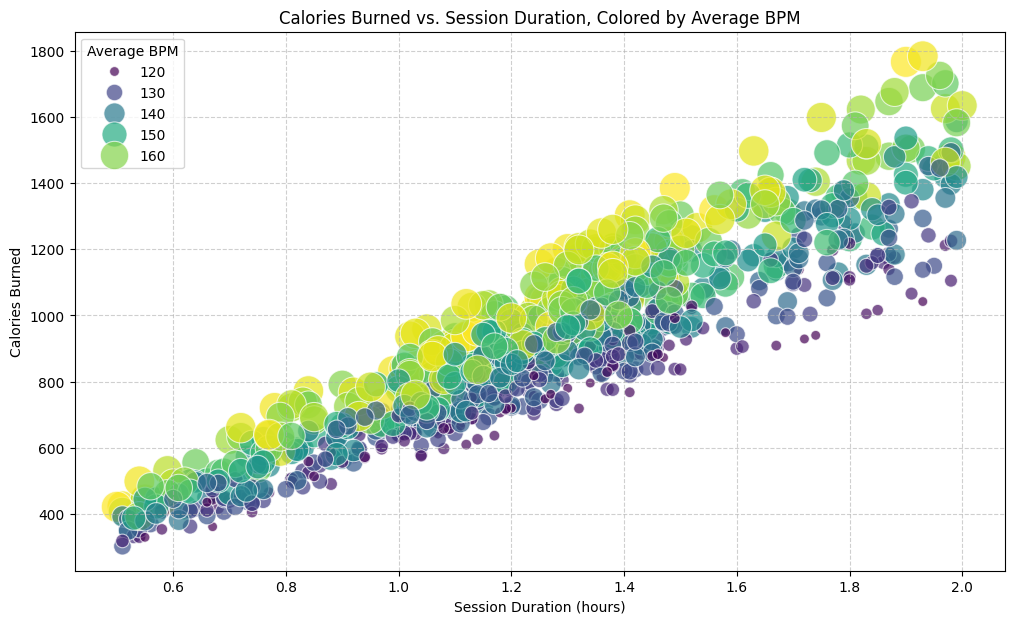

In [9]:
plt.figure(figsize=(12, 7))
sns.scatterplot(x='Session_Duration (hours)', y='Calories_Burned', hue='Avg_BPM', size='Avg_BPM', data=df, palette='viridis', sizes=(50, 500), alpha=0.7)
plt.title('Calories Burned vs. Session Duration, Colored by Average BPM')
plt.xlabel('Session Duration (hours)')
plt.ylabel('Calories Burned')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Average BPM')
plt.show()

**מסקנה מהגרף (Scatter Plot משולב):**

גרף זה מציג באופן ויזואלי חזק את הקשרים המרובים המשפיעים על שריפת קלוריות:

*   **משך אימון וקלוריות נשרפות:** ניתן לראות בבירור קשר חיובי בין משך האימון לבין כמות הקלוריות הנשרפות. ככל שהאימון ארוך יותר, כך שריפת הקלוריות גבוהה יותר.

*   **השפעת קצב הלב הממוצע:** בנוסף למשך האימון, צבע הנקודות מייצג את קצב הלב הממוצע (Avg_BPM).  רואים שככל שהנקודות כהות יותר (קצב לב ממוצע גבוה יותר), כך הקלוריות הנשרפות גבוהות יותר, גם באותו משך אימון.

*   **יעילות האימון:** הגרף ממחיש שאנשים שמתאמנים זמן רב יותר ובאינטנסיביות גבוהה יותר (קצב לב ממוצע גבוה) שורפים את כמות הקלוריות הגדולה ביותר. לדוגמה, אימון שנמשך 1.5 שעות עם קצב לב גבוה (נקודות כהות) יביא לשריפת קלוריות רבה יותר מאימון באותו משך עם קצב לב נמוך (נקודות בהירות).

גרף זה מסכם בצורה מצוינת את ההשפעה המשולבת של משך ואינטנסיביות האימון על שריפת קלוריות, ומתאים מאוד להצגת מסקנות ברורות.

משתנה בדיד

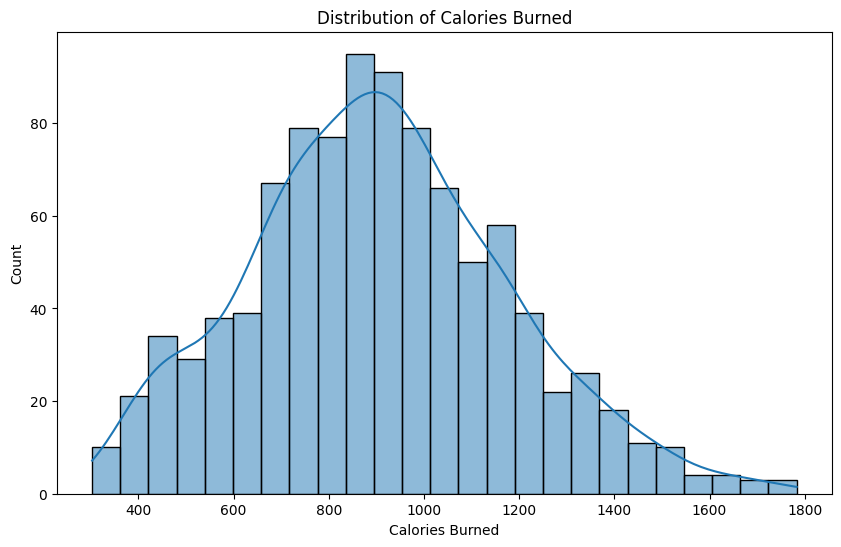

In [10]:
plt.figure(figsize=(10,6))
sns.histplot(df["Calories_Burned"], bins=25, kde=True)
plt.title("Distribution of Calories Burned")
plt.xlabel("Calories Burned")
plt.ylabel("Count")
plt.show()


**מהגרף רואים שרוב הערכים של Calories_Burned נמצאים בערך בין 600 ל-1100 קלוריות.
הטווח שהכי חוזר (הכי הרבה נקודות/עמודות) הוא בערך באזור 850–950 קלוריות, כלומר זה הכי נפוץ בדאטה.**


**רוב האימונים שורפים כמות רגילה/ממוצעת של קלוריות, ורק מעט מקרים הם ממש נמוכים או ממש גבוהים.**



משתנה בדיד

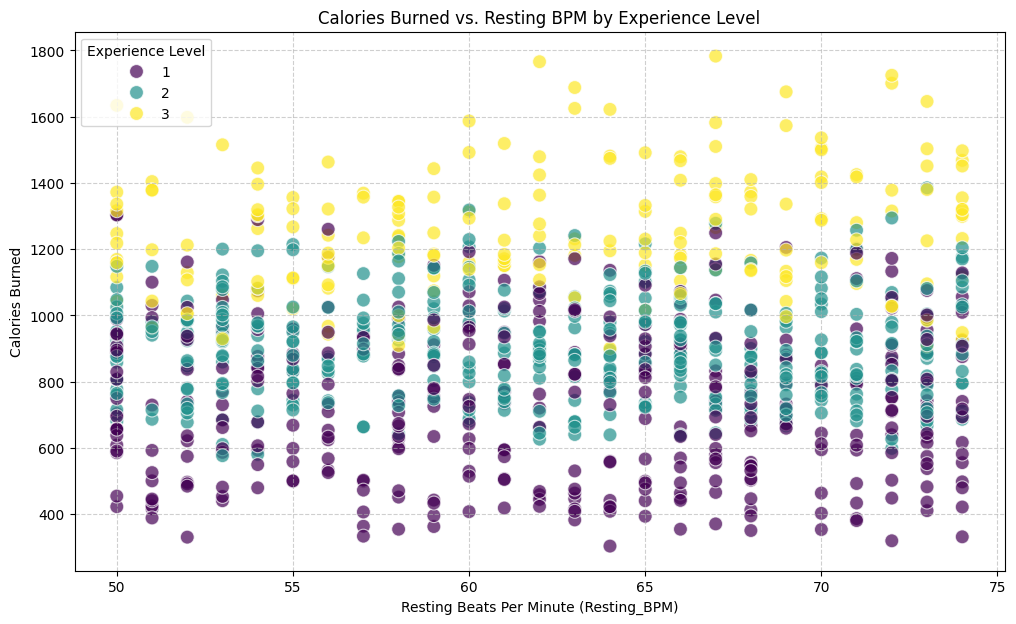

In [11]:
plt.figure(figsize=(12, 7))
sns.scatterplot(x='Resting_BPM', y='Calories_Burned', hue='Experience_Level', data=df, palette='viridis', s=100, alpha=0.7)
plt.title('Calories Burned vs. Resting BPM by Experience Level')
plt.xlabel('Resting Beats Per Minute (Resting_BPM)')
plt.ylabel('Calories Burned')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Experience Level')
plt.show()

**מסקנה מהגרף (Scatter Plot - קלוריות שנשרפו מול דופק במנוחה לפי רמת ניסיון):**

הגרף הזה מראה לנו קשר מעניין בין דופק במנוחה, רמת ניסיון ושריפת קלוריות:

*   **דופק במנוחה וקלוריות:** ישנה מגמה כללית (לא מאוד חזקה אבל קיימת) שאנשים עם דופק נמוך יותר במנוחה (מה שלרוב מצביע על כושר טוב יותר) נוטים לשרוף יותר קלוריות באימון. זה הגיוני, כי הם כנראה יכולים להתאמן חזק יותר או לאורך זמן רב יותר.

*   **רמת ניסיון:** הצבעים בגרף מבהירים את ההשפעה של רמת הניסיון:
    *   **מתחילים (רמה 1):** נמצאים בעיקר באזורים עם דופק במנוחה גבוה יותר ושריפת קלוריות נמוכה יותר.
    *   **מתקדמים (רמה 2) ומקצוענים (רמה 3):** נוטים להיות באזורים עם דופק במנוחה נמוך יותר ושריפת קלוריות גבוהה יותר. המקצוענים (רמה 3) מציגים את השילוב הטוב ביותר של דופק נמוך במנוחה ושריפת קלוריות גבוהה.

*   **מה לומדים מזה?** נראה שאנשים עם כושר בסיסי טוב יותר (דופק נמוך במנוחה) ורמת ניסיון גבוהה יותר מצליחים לשרוף יותר קלוריות באימונים. זה מחזק את הרעיון שכושר כללי וניסיון הם גורמים חשובים כשזה מגיע ליעילות שריפת קלוריות.

# הינדוס נתונים

In [12]:
df.shape


(973, 15)

בדאטה קיימות 973 רשומות (אימונים/מתאמנים) ו-15 עמודות (מאפיינים).

In [13]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    object 
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    object 
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int

מתוך 15 העמודות, יש 2 עמודות קטגוריאליות מסוג object (Gender, Workout_Type) והשאר עמודות מספריות (int/float).

In [14]:
df.describe()


,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


לפי הסטטיסטיקה התיאורית, גיל המתאמנים נע בין 18 ל-59, ומשקל נע בין 40 ל-129.9 ק״ג.
משך האימון נע בין 0.5 ל-2 שעות, וכמות הקלוריות שנשרפו (Calories_Burned) נעה בין 303 ל-1783 עם ממוצע של בערך 905.

In [15]:
df.isnull().sum()

,0
Age,0
Gender,0
Weight (kg),0
Height (m),0
Max_BPM,0
Avg_BPM,0
Resting_BPM,0
Session_Duration (hours),0
Calories_Burned,0
Workout_Type,0


בדקתי אם יש נתונים חסרים (Null) וגיליתי שאין בכלל – בכל העמודות יצא 0.
בגלל זה לא צריך עכשיו למחוק שורות או להשלים ערכים, ואפשר להתמקד בדברים אחרים כמו לבדוק אם יש ערכים מוזרים/לא הגיוניים ולהכין את הנתונים ללמידת מכונה.

In [16]:
df['Gender'].value_counts()


,count
Gender,
Male,511
Female,462


בדקתי כמה גברים וכמה נשים יש בדאטה: יש 511 גברים ו-462 נשים.
זה די מאוזן, וזה טוב כי המודל לא “ילמד” יותר מדי לכיוון מגדר אחד.

In [17]:
df['Workout_Type'].value_counts()


,count
Workout_Type,
Strength,258
Cardio,255
Yoga,239
HIIT,221


יש בדאטה 4 סוגי אימון: Strength, Cardio, Yoga ו-HIIT.
הכמויות די דומות (בערך 221–258 לכל סוג), וזה טוב כי המודל יקבל מספיק דוגמאות מכל סוג כדי להבין איך זה משפיע על שריפת קלוריות.

In [18]:
df['Experience_Level'].value_counts()


,count
Experience_Level,
2,406
1,376
3,191


ברמת ניסיון, הכי הרבה זה רמה 2 (406), אחריה רמה 1 (376), והכי מעט זה רמה 3 (191).
זאת אומרת שיש פחות מתאמנים מקצועיים בדאטה, אז אם נשתמש בזה בהמשך צריך לזכור שהרמה 3 קצת פחות מיוצגת.

**שינוי המין מגבר ואישה למספרים 1,0**

In [19]:
df['Gender']=df['Gender'].replace({'Male':0,'Female':1})
df

/tmp/ipykernel_1383/3585171075.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Gender']=df['Gender'].replace({'Male':0,'Female':1})


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,0,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,1,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,1,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,0,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,0,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
968,24,0,87.1,1.74,187,158,67,1.57,1364.0,Strength,10.0,3.5,4,3,28.77
969,25,0,66.6,1.61,184,166,56,1.38,1260.0,Strength,25.0,3.0,2,1,25.69
970,59,1,60.4,1.76,194,120,53,1.72,929.0,Cardio,18.8,2.7,5,3,19.50
971,32,0,126.4,1.83,198,146,62,1.10,883.0,HIIT,28.2,2.1,3,2,37.74


שיניתי את העמודה Gender למספרים כדי שהמודלים יוכלו לעבוד: Male = 0, Female = 1.

**שינוי סוג האימון למספר**

In [20]:
df= pd.get_dummies(df, dtype = int)
df

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Workout_Type_Cardio,Workout_Type_HIIT,Workout_Type_Strength,Workout_Type_Yoga
0,56,0,88.3,1.71,180,157,60,1.69,1313.0,12.6,3.5,4,3,30.20,0,0,0,1
1,46,1,74.9,1.53,179,151,66,1.30,883.0,33.9,2.1,4,2,32.00,0,1,0,0
2,32,1,68.1,1.66,167,122,54,1.11,677.0,33.4,2.3,4,2,24.71,1,0,0,0
3,25,0,53.2,1.70,190,164,56,0.59,532.0,28.8,2.1,3,1,18.41,0,0,1,0
4,38,0,46.1,1.79,188,158,68,0.64,556.0,29.2,2.8,3,1,14.39,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
968,24,0,87.1,1.74,187,158,67,1.57,1364.0,10.0,3.5,4,3,28.77,0,0,1,0
969,25,0,66.6,1.61,184,166,56,1.38,1260.0,25.0,3.0,2,1,25.69,0,0,1,0
970,59,1,60.4,1.76,194,120,53,1.72,929.0,18.8,2.7,5,3,19.50,1,0,0,0
971,32,0,126.4,1.83,198,146,62,1.10,883.0,28.2,2.1,3,2,37.74,0,1,0,0


** "One-Hot Encoding"שנינו את שני נתונים אלו לנתונים מספריים כדי שיהיה אפשר לעבוד איתם**

In [21]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    int64  
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Fat_Percentage                 973 non-null    float64
 10  Water_Intake (liters)          973 non-null    float64
 11  Workout_Frequency (days/week)  973 non-null    int64  
 12  Experience_Level               973 non-null    int

# **מחיקת ערכי קיצון**

**נבדוק האם יש ערכי קיצון**

In [22]:
calories = df['Calories_Burned']
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outliers = (df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))
outlier_count = outliers.sum()
print(outlier_count)

Age                                0
Gender                             0
Weight (kg)                        9
Height (m)                         0
Max_BPM                            0
Avg_BPM                            0
Resting_BPM                        0
Session_Duration (hours)           0
Calories_Burned                   10
Fat_Percentage                     0
Water_Intake (liters)              0
Workout_Frequency (days/week)      0
Experience_Level                   0
BMI                               25
Workout_Type_Cardio                0
Workout_Type_HIIT                221
Workout_Type_Strength              0
Workout_Type_Yoga                239
dtype: int64


** נבדוק מה הם ערכי הקיצון, אם הם משפיעים מדי נמחק אותם**

**עמודת המשקל**

In [23]:
Q1 = df['Weight (kg)'].quantile(0.25)
Q3 = df['Weight (kg)'].quantile(0.75)
IQR = Q3 - Q1
outliers = (df['Weight (kg)'] < (Q1 - 1.5 * IQR)) | (df['Weight (kg)'] > (Q3 + 1.5 * IQR))
outlier_values_only = df['Weight (kg)'][outliers]
print(outlier_values_only)

96     129.0
122    129.5
180    128.2
283    128.4
291    128.4
593    129.9
614    128.4
648    127.9
854    129.2
Name: Weight (kg), dtype: float64


**המשקלים הללו אומנם גבוהים אך לא קיצוניים ולכן נשאיר אותם**

**עמודת שריפת הקלוריות**

In [24]:
Q1 = df['Calories_Burned'].quantile(0.25)
Q3 = df['Calories_Burned'].quantile(0.75)
IQR = Q3 - Q1
outliers = (df['Calories_Burned'] < (Q1 - 1.5 * IQR)) | (df['Calories_Burned'] > (Q3 + 1.5 * IQR))
outlier_values_only = df['Calories_Burned'][outliers]
print(outlier_values_only)

90     1688.0
99     1625.0
124    1701.0
475    1622.0
511    1725.0
572    1646.0
646    1675.0
712    1766.0
728    1634.0
910    1783.0
Name: Calories_Burned, dtype: float64


**כמויות הקלרויות הגבהות שנשרפו הן לא מספיק גבוהות בשביל שנמחק אותם**

**BMI עמודת מחשבון ה**

In [25]:
Q1 = df['BMI'].quantile(0.25)
Q3 = df['BMI'].quantile(0.75)
IQR = Q3 - Q1
outliers = (df['BMI'] < (Q1 - 1.5 * IQR)) | (df['BMI'] > (Q3 + 1.5 * IQR))
outlier_values_only = df['BMI'][outliers]
print(outlier_values_only)

10     43.31
12     43.40
35     42.63
55     44.84
133    45.43
251    45.14
261    47.72
291    45.49
302    43.31
345    44.71
445    41.60
470    46.90
524    42.30
593    43.40
603    41.84
687    45.14
710    46.98
718    41.34
833    44.26
854    49.84
868    46.94
916    41.56
924    44.10
936    44.66
945    48.43
Name: BMI, dtype: float64


**התוצאות אכן גבוהות מאוד אך הן לא מספיק גבוהות בשביל שיחשבו ערכי קיצון שצריך למחוק אותם**

# **קורלציה**

**נבדוק את הקורלציה של הערכים**

<Axes: >

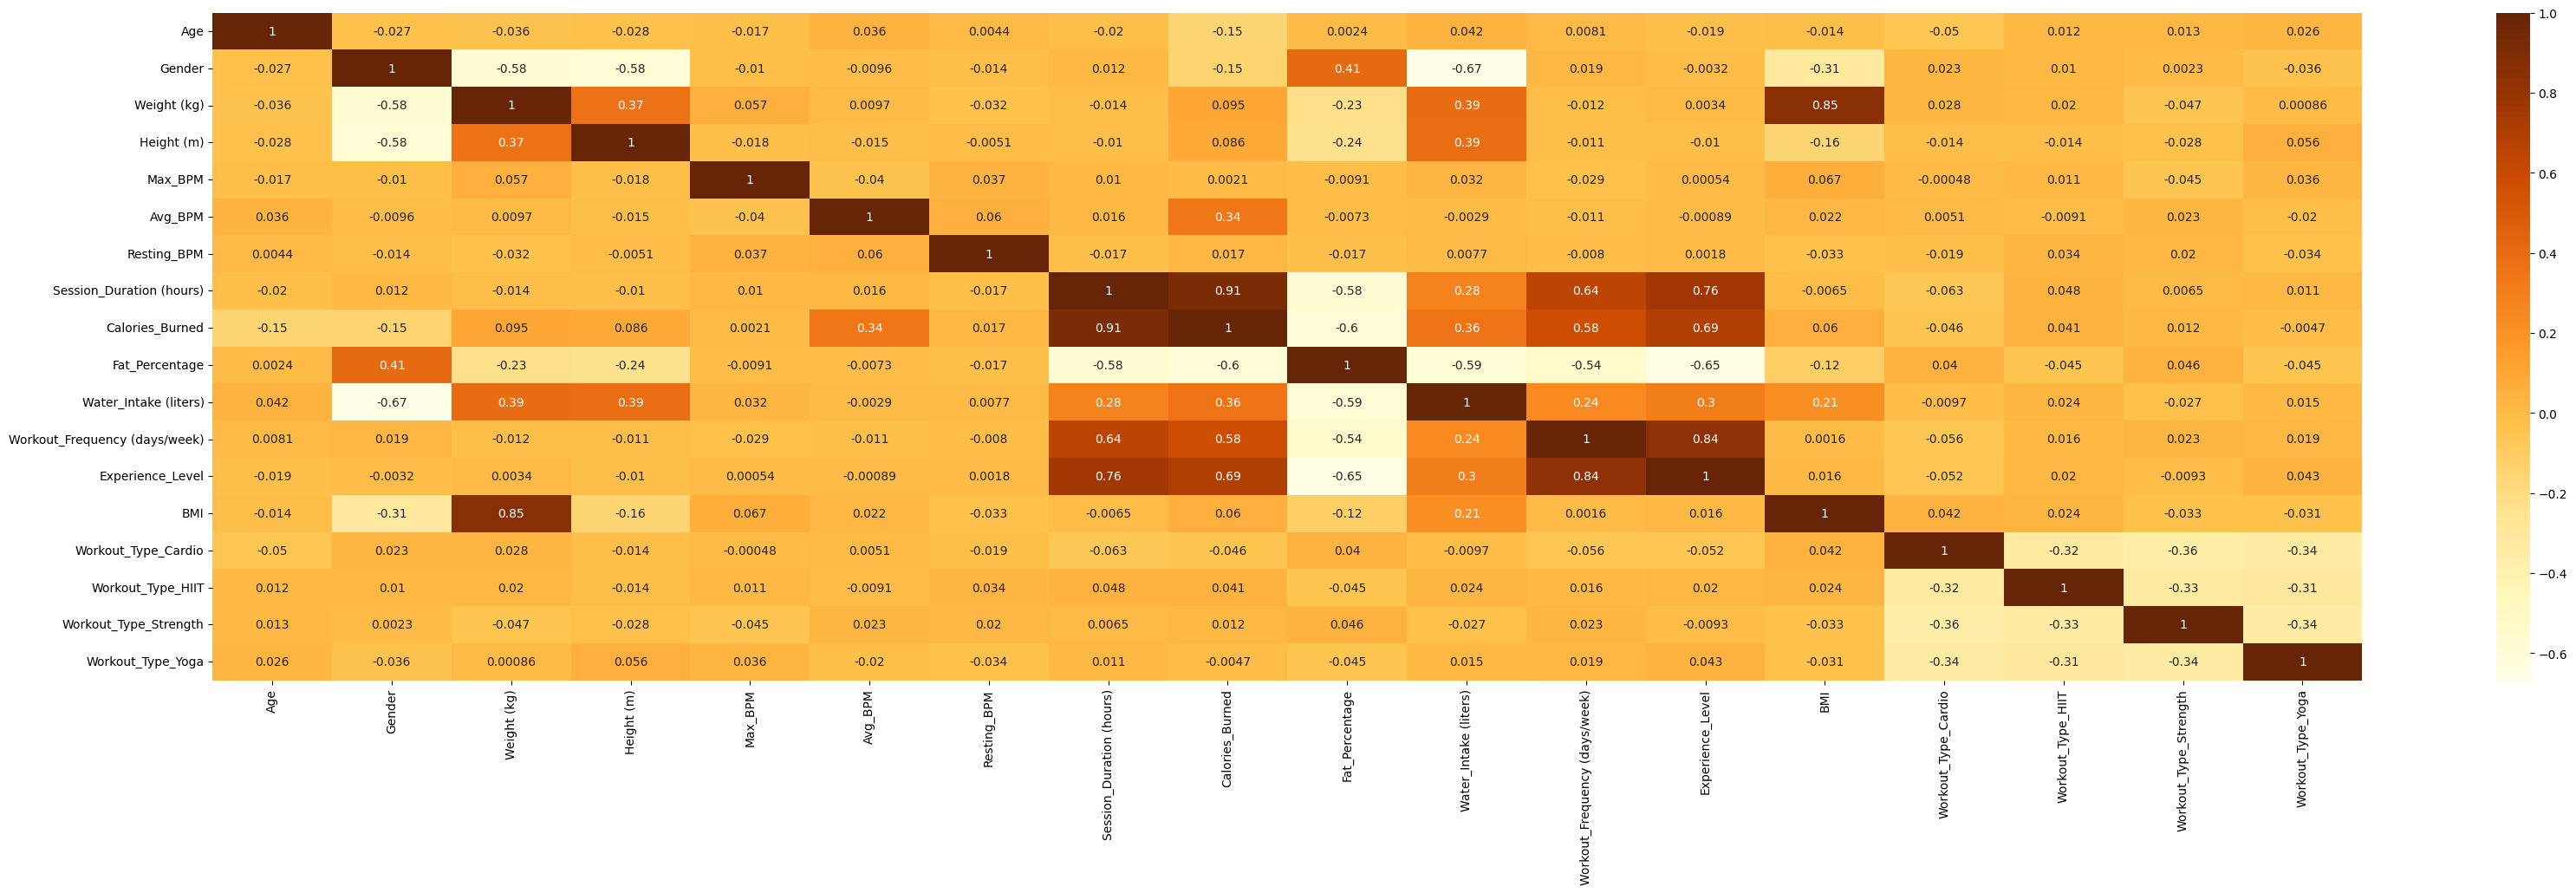

In [26]:
plt.figure(figsize = (40,10))
corr = df.corr()
sns.heatmap(corr,annot=True,cmap='YlOrBr')

In [27]:
df.corr()[['Calories_Burned']].sort_values('Calories_Burned',ascending=False)

,Calories_Burned
Calories_Burned,1.000000
Session_Duration (hours),0.908140
Experience_Level,0.694129
Workout_Frequency (days/week),0.576150
Water_Intake (liters),0.356931
Avg_BPM,0.339659
Weight (kg),0.095443
Height (m),0.086348
BMI,0.059761
Workout_Type_HIIT,0.040550


**קורולציה מראה את ההשפעה על שריפת קלוריות מהנתון שמשפיעהכיהרבה בצורה חיובית לנתון שמפיע בצורה שלילית**

**נמחק כל ערך שמתחת ל0.01**

In [28]:
corr_matrix = df.corr()
price_corr = corr_matrix['Calories_Burned'].abs().sort_values(ascending=False)
threshold = 0.01
columns_to_drop = price_corr[price_corr < threshold].index.tolist()
df = df.drop(columns=columns_to_drop)
df

,Age,Gender,Weight (kg),Height (m),Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Workout_Type_Cardio,Workout_Type_HIIT,Workout_Type_Strength
0,56,0,88.3,1.71,157,60,1.69,1313.0,12.6,3.5,4,3,30.20,0,0,0
1,46,1,74.9,1.53,151,66,1.30,883.0,33.9,2.1,4,2,32.00,0,1,0
2,32,1,68.1,1.66,122,54,1.11,677.0,33.4,2.3,4,2,24.71,1,0,0
3,25,0,53.2,1.70,164,56,0.59,532.0,28.8,2.1,3,1,18.41,0,0,1
4,38,0,46.1,1.79,158,68,0.64,556.0,29.2,2.8,3,1,14.39,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
968,24,0,87.1,1.74,158,67,1.57,1364.0,10.0,3.5,4,3,28.77,0,0,1
969,25,0,66.6,1.61,166,56,1.38,1260.0,25.0,3.0,2,1,25.69,0,0,1
970,59,1,60.4,1.76,120,53,1.72,929.0,18.8,2.7,5,3,19.50,1,0,0
971,32,0,126.4,1.83,146,62,1.10,883.0,28.2,2.1,3,2,37.74,0,1,0


# **Prepring for test**

**נחלק את כמות הקלוריות שנשרפו ל5 קבוצות**

In [29]:
df['Calories_Burned']=pd.qcut(df['Calories_Burned'],q=5,labels=False, duplicates='drop')
df= df.sample(frac=1,random_state=42).reset_index(drop=True)
min_count=df['Calories_Burned'].value_counts().min()
df=df.groupby('Calories_Burned',group_keys=False).apply(lambda x: x.sample(n=min_count,random_state=42)).reset_index(drop=True)
df['Calories_Burned'].value_counts()

/tmp/ipykernel_1383/4136380900.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df=df.groupby('Calories_Burned',group_keys=False).apply(lambda x: x.sample(n=min_count,random_state=42)).reset_index(drop=True)


,count
Calories_Burned,
0,192
1,192
2,192
3,192
4,192


**נמחק את העמודה שאנו בודקים**

In [30]:
X=df.drop(['Calories_Burned'],axis=1).to_numpy()
y=df['Calories_Burned'].to_numpy()
print("start:",X.shape,y.shape)

start: (960, 15) (960,)


**נחלק את הנתונים כך שנחזה 20 אחוז**

In [31]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)
print("train: ", X_train.shape,y_train.shape)
print("test: ", X_test.shape,y_test.shape)

train:  (768, 15) (768,)
test:  (192, 15) (192,)


**נירמול**

In [32]:
scaler=MinMaxScaler()
print("Before scaling:")
print('Max: ',X_train.max())
print('Min: ',X_train.min())
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)
print("\nEverything has been scaled between 1 and 0")
print('Max: ',X_train.max())
print('Min: ',X_train.min())

Before scaling:
Max:  169.0
Min:  0.0

Everything has been scaled between 1 and 0
Max:  1.0
Min:  0.0


**נרמלנו כדי שלכל הנתונים יהיו סוג של מכנה משותף כדי שיהיה אפשר לחזות איתם חיזוי טוב**

# **Training and evaluation**

**נבדוק את החיזוי עבור כל ערך בין 3 ל 30**

In [33]:
for k in range (3,30):
  knn1=KNeighborsClassifier(n_neighbors=k)
  knn1.fit(X_train,y_train)
  print("k={} score test: {}".format(k,knn1.score(X_test,y_test)))

k=3 score test: 0.4635416666666667
k=4 score test: 0.4427083333333333
k=5 score test: 0.4583333333333333
k=6 score test: 0.4635416666666667
k=7 score test: 0.4791666666666667
k=8 score test: 0.453125
k=9 score test: 0.421875
k=10 score test: 0.4114583333333333
k=11 score test: 0.4479166666666667
k=12 score test: 0.4479166666666667
k=13 score test: 0.4635416666666667
k=14 score test: 0.4635416666666667
k=15 score test: 0.4479166666666667
k=16 score test: 0.4322916666666667
k=17 score test: 0.4375
k=18 score test: 0.4479166666666667
k=19 score test: 0.421875
k=20 score test: 0.421875
k=21 score test: 0.4479166666666667
k=22 score test: 0.4322916666666667
k=23 score test: 0.4375
k=24 score test: 0.4479166666666667
k=25 score test: 0.453125
k=26 score test: 0.421875
k=27 score test: 0.4270833333333333
k=28 score test: 0.4166666666666667
k=29 score test: 0.421875


**החיזוי לא טוב ובכל זאת נמשיך**

**ניקח את החוזה הטוב ביותר**

In [34]:
best_k=7
knn1 = KNeighborsClassifier(n_neighbors = best_k)  #best param
knn1.fit(X_train,y_train)
print("k = {} score test: {}".format(best_k,knn1.score(X_test, y_test)))

k = 7 score test: 0.4791666666666667


**נבדוק איך המחשב חוזה לאיזה קבוצת שריפת קלוריות המחשב משייך כמות  אנשים**

In [35]:
pred1=knn1.predict(X_test)
confusion_matrix(pred1,y_test)

array([[24, 16,  6,  1,  0],
       [ 4, 16, 11,  7,  0],
       [ 4, 14, 13,  5,  3],
       [ 1,  4,  9, 10,  5],
       [ 0,  0,  1,  9, 29]])

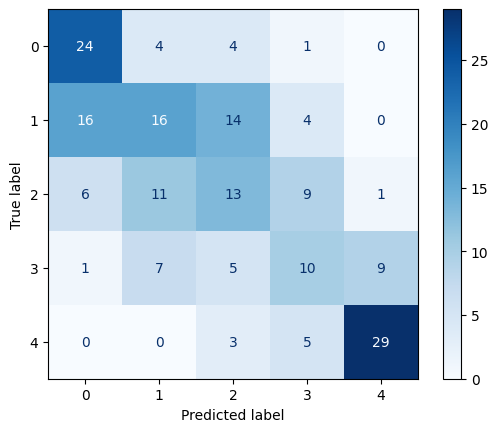

In [36]:
ConfusionMatrixDisplay.from_estimator(knn1, X_test, y_test,values_format="d",cmap='Blues');

**ניתן לראות שהמחשב לא חזה טוב כמצופה כמובן**

**גם אפשר לראות שאת הקבוצות הקיצוניות (0,5) הוא חזה טוב שלא כמו האמצעי (1,2,3)**

**וזה בגלל שהקבוצות האמצעיות מאוד דומות בנתונים שלהם לקבוצה העוקבת והקודמת להם**

**החיזוי**

In [37]:
pred1 = knn1.predict(X_test)
print(classification_report(y_test,pred1,digits=4))

              precision    recall  f1-score   support

           0     0.5106    0.7273    0.6000        33
           1     0.4211    0.3200    0.3636        50
           2     0.3333    0.3250    0.3291        40
           3     0.3448    0.3125    0.3279        32
           4     0.7436    0.7838    0.7632        37

    accuracy                         0.4792       192
   macro avg     0.4707    0.4937    0.4768       192
weighted avg     0.4676    0.4792    0.4681       192



presicion- מדד שמצביע על כמה מהחיזויים עבור אותה קטגוריה שהמודל שהמודל עשה היו נכונים

recall- מודד כמה פעמים המחשב ניחש את הקטגוריה הנכונה לעומת כמות הפעמים שהיא הופיעה בנתונים

support- כמה דוגמאות היו מאותה קטגוריה

**ולכן נתייחס לעמודה זו presicion ו recall היא שכלול של f1-score**

ניתן לראות כי קבוצות הקצה (0,4) המחשב חזה אותם יותר טוב בהפרש ניכר מהשאר ככל הנראה כי הן לא קרובות לנתונים שלהם לשאר הקטגוריות למשל קטגוריה מספר 4 קרובה רק לקטגוריה מספר 3 ואין הרבה איפה לטעות אך קטגוריה מספר 3 קרובה גם לקטגוריה 4 וגם לקטגוריה 2 ושם יש הרבה איפה לטעות


**החיזוי שיצא לא טוב ולכן ננסה לתקן ולשפר את החיזוי**

# **תיקון ושיפור החיזוי**

**לאור התוצאות נמחק כל ערך שקטן מ0.2**

In [38]:
corr_matrix = df.corr()
price_corr = corr_matrix['Calories_Burned'].abs().sort_values(ascending=False)
threshold = 0.2
columns_to_drop = price_corr[price_corr < threshold].index.tolist()
df = df.drop(columns=columns_to_drop)
df

,Avg_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level
0,120,1.11,0,29.9,1.7,3,2
1,141,0.84,0,24.4,3.5,3,1
2,143,0.57,0,26.9,2.9,3,1
3,130,1.10,0,28.8,2.2,3,1
4,123,0.97,0,29.2,2.4,2,1
...,...,...,...,...,...,...,...
955,156,1.34,4,21.4,2.3,3,2
956,153,1.67,4,17.8,2.7,4,3
957,162,1.32,4,21.0,3.6,4,2
958,161,1.42,4,26.8,2.9,4,2




**נחלק ל 3 קבוצות**

In [39]:
df['Calories_Burned']=pd.qcut(df['Calories_Burned'],q=3,labels=False, duplicates='drop')
df= df.sample(frac=1,random_state=42).reset_index(drop=True)
min_count=df['Calories_Burned'].value_counts().min()
df=df.groupby('Calories_Burned',group_keys=False).apply(lambda x: x.sample(n=min_count,random_state=42)).reset_index(drop=True)
df['Calories_Burned'].value_counts()

/tmp/ipykernel_1383/1248951385.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df=df.groupby('Calories_Burned',group_keys=False).apply(lambda x: x.sample(n=min_count,random_state=42)).reset_index(drop=True)


,count
Calories_Burned,
0,192
1,192
2,192


הורדנו את כמות הקבוצות כדי שלמחשב יהיה יותר קל לחזות

In [40]:
df

,Avg_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level
0,124,0.90,0,33.7,1.9,3,1
1,140,0.77,0,27.6,3.6,2,1
2,127,1.03,0,28.9,2.6,4,2
3,122,1.11,0,33.4,2.3,4,2
4,163,0.85,0,31.1,1.5,3,1
...,...,...,...,...,...,...,...
571,123,1.77,2,13.2,3.5,4,3
572,155,1.48,2,20.9,2.9,2,1
573,160,1.96,2,10.2,3.5,5,3
574,141,1.85,2,17.8,2.7,4,3


In [41]:
X=df.drop(['Calories_Burned'],axis=1).to_numpy()
y=df['Calories_Burned'].to_numpy()
print("start:",X.shape,y.shape)

start: (576, 6) (576,)


**נחלק שוב לקבוצת חיזוי וקבוצת אימון**

In [42]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)
print("train: ", X_train.shape,y_train.shape)
print("test: ", X_test.shape,y_test.shape)

train:  (460, 6) (460,)
test:  (116, 6) (116,)


**ננרמל שוב**

In [43]:
scaler=MinMaxScaler()
print("Before scaling:")
print('Max: ',X_train.max())
print('Min: ',X_train.min())
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)
print("\nEverything has been scaled between 1 and 0")
print('Max: ',X_train.max())
print('Min: ',X_train.min())

Before scaling:
Max:  169.0
Min:  0.5

Everything has been scaled between 1 and 0
Max:  1.0
Min:  0.0


In [44]:
for k in range (3,30):
  knn1=KNeighborsClassifier(n_neighbors=k)
  knn1.fit(X_train,y_train)
  print("k={} score test: {}".format(k,knn1.score(X_test,y_test)))

k=3 score test: 0.8103448275862069
k=4 score test: 0.7758620689655172
k=5 score test: 0.7931034482758621
k=6 score test: 0.8103448275862069
k=7 score test: 0.8189655172413793
k=8 score test: 0.8189655172413793
k=9 score test: 0.8275862068965517
k=10 score test: 0.8448275862068966
k=11 score test: 0.8275862068965517
k=12 score test: 0.8275862068965517
k=13 score test: 0.8189655172413793
k=14 score test: 0.8362068965517241
k=15 score test: 0.8275862068965517
k=16 score test: 0.8362068965517241
k=17 score test: 0.8362068965517241
k=18 score test: 0.8103448275862069
k=19 score test: 0.8275862068965517
k=20 score test: 0.8189655172413793
k=21 score test: 0.8189655172413793
k=22 score test: 0.8189655172413793
k=23 score test: 0.8189655172413793
k=24 score test: 0.8189655172413793
k=25 score test: 0.8017241379310345
k=26 score test: 0.8017241379310345
k=27 score test: 0.8017241379310345
k=28 score test: 0.7931034482758621
k=29 score test: 0.8017241379310345


**החיזוי טוב יותר**

**ניקח את החוזה הטוב ביותר**

In [45]:
best_k=7
knn1 = KNeighborsClassifier(n_neighbors = best_k)
knn1.fit(X_train,y_train)
print("k = {} score test: {}".format(best_k,knn1.score(X_test, y_test)))

k = 7 score test: 0.8189655172413793


**נבדוק שוב נבדוק איך המחשב חוזה לאיזה קבוצת שריפת קלוריות המחשב משייך כמות אנשים**

In [46]:
pred1=knn1.predict(X_test)
confusion_matrix(pred1,y_test)

array([[30,  6,  0],
       [ 8, 27,  4],
       [ 0,  3, 38]])

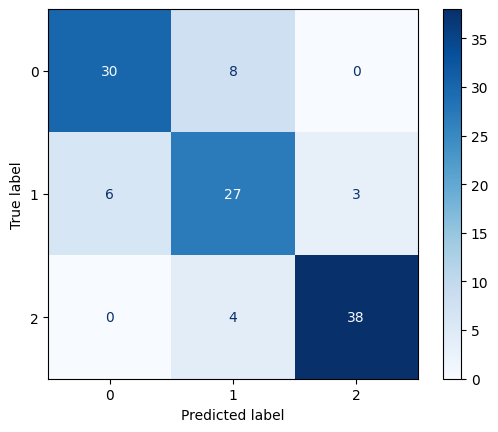

In [47]:
ConfusionMatrixDisplay.from_estimator(knn1, X_test, y_test,values_format="d",cmap='Blues');

**קבוצה מספר 1 היא בעלת הסיווג הגרוע ביותר, ניתן לראות כי הסיווג של קבוצות 0,2 הוא דומה יחסית**

**קבוצה 1 פחות טובה כי הנתונים שלהם קרובים ודומים לנתונים של שאר הקבוצות ולכן גם הסטיות של קבוצות 0,2 הם רק לקבוצה 1**

**החיזוי**

In [48]:
pred1 = knn1.predict(X_test)
print(classification_report(y_test,pred1,digits=4))

              precision    recall  f1-score   support

           0     0.8333    0.7895    0.8108        38
           1     0.6923    0.7500    0.7200        36
           2     0.9268    0.9048    0.9157        42

    accuracy                         0.8190       116
   macro avg     0.8175    0.8147    0.8155       116
weighted avg     0.8234    0.8190    0.8206       116



ניתן לראות שמהמגמה שנראת בחיזוי הקודם נשמרה שבה קטגוריות הקצה בעלות חיזוי טוב יותר מאשר הקטגוריה באמצע

# **ANN**

**נזיז את עמודת הסיווג כך שתיהיה בסוף הטבלה לצורך החיזוי**

In [49]:
cols = list(df.columns)
cols.remove('Calories_Burned')
cols.append('Calories_Burned')
df = df[cols]
df

,Avg_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,Calories_Burned
0,124,0.90,33.7,1.9,3,1,0
1,140,0.77,27.6,3.6,2,1,0
2,127,1.03,28.9,2.6,4,2,0
3,122,1.11,33.4,2.3,4,2,0
4,163,0.85,31.1,1.5,3,1,0
...,...,...,...,...,...,...,...
571,123,1.77,13.2,3.5,4,3,2
572,155,1.48,20.9,2.9,2,1,2
573,160,1.96,10.2,3.5,5,3,2
574,141,1.85,17.8,2.7,4,3,2


**נראה את העמודות ללא עמודת הסיווג וגם נראה את הופעות הקטגוריות הסיווג**

In [50]:
X = df.iloc[:,:6].to_numpy()
y = df.loc[:,['Calories_Burned']].to_numpy().reshape(1,-1).flatten()
print(X)
print(y)

[[124.     0.9   33.7    1.9    3.     1.  ]
 [140.     0.77  27.6    3.6    2.     1.  ]
 [127.     1.03  28.9    2.6    4.     2.  ]
 ...
 [160.     1.96  10.2    3.5    5.     3.  ]
 [141.     1.85  17.8    2.7    4.     3.  ]
 [161.     1.62  19.8    2.7    5.     3.  ]]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 

**נשלח 80 אחוז לאימון ו20 אחוז לחיזוי**

**נוסיף גרפים ומספר נוירונים**

**נראה גם איך זה חוזה**

In [51]:
y = to_categorical(y)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
model = Sequential([
      Dense(512, activation='relu', input_shape=(6,)),
      Dense(256, activation='selu'),
      Dense(128, activation='gelu'),
      Dense(64, activation='selu'),
      Dense(16, activation='relu'),
      Dense(3, activation='softmax')
   ])
model.compile(
      optimizer='Adam',
      loss= 'categorical_crossentropy',
      metrics=['accuracy']
   )
print(y, y.shape)

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 ...
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]] (576, 3)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**הוספתי 6 גרפים ושכבות לחיזוי כי עם 4 החיזוי עבד פחות טוב**

**בחרתי בגרפים הספציפים האלה כי איתם החיזוי עבד הכי טוב**

**נתחיל את פעולת החיזוי ונעשה אותה 200 פעמים**

In [52]:
history  = model.fit(
    x=x_train,
    y=y_train,
    epochs=200,
    shuffle=True
)

Epoch 1/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.3326 - loss: 3.8143
Epoch 2/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4500 - loss: 1.1135
Epoch 3/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5543 - loss: 0.8614
Epoch 4/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5304 - loss: 0.8666
Epoch 5/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5565 - loss: 0.9205
Epoch 6/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5457 - loss: 0.9173
Epoch 7/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5783 - loss: 0.7989
Epoch 8/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6326 - loss: 0.7367
Epoch 9/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5870 - loss: 0.7914
Epoch 10/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6000 - loss: 0.7385
Epoch 11/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6152 - loss: 0.7526
Epoch 12/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy:

**חזינו 200 פעמים כי כך זה עבד בצורה הטובה ביותר**

**נבדוק עבור ערך פיקטיבי הקרוב יחסית בנתוניו לקבוצה מספר 2 של החיזוי**

In [53]:
score = model.evaluate(x_test, y_test, verbose = 0)
score_train = model.evaluate(x_train, y_train, verbose = 0)

print('Test loss:', score[0])
print('Test accuracy:', score[1])

answer = model.predict(np.array([133,2.5,14.5,4,3,2]).reshape(-1, 1).T)
print("[133,2.5,2,14.5,4,3,2]",answer)

print(history.history.keys())
acc=history.history['accuracy']
print("accuracy - train",score_train[1])

loss=history.history['loss']

Test loss: 0.35823729634284973
Test accuracy: 0.818965494632721
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
[133,2.5,2,14.5,4,3,2] [[4.2439645e-08 3.6540214e-04 9.9963450e-01]]
dict_keys(['accuracy', 'loss'])
accuracy - train 0.8782608509063721


**ניתן לראות שקבוצה מספר 2 היא בעלת המספר הגבוה ביותר מאחר שמחשב גילה שהנתון הפיקטיבי הוא מקבוצה 2 כפי שעשינו**

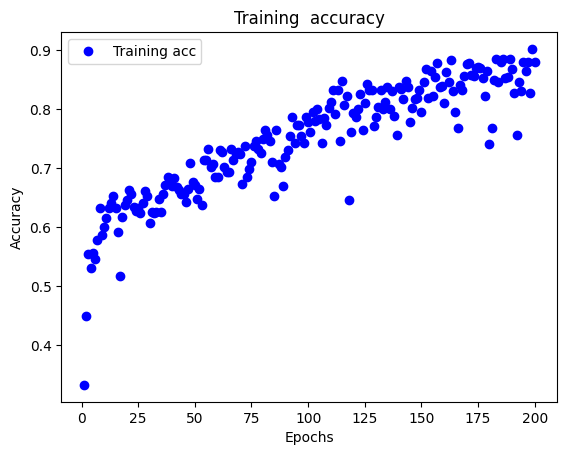

In [54]:
epochs=range(1,len(acc)+1)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.title('Training  accuracy')
plt.legend()
plt.show()

**ניתן לראות מהגרף שהתוצאות החיזוי עולות עם כמות הפעמים שהמחשב חוזה אך יש גם נקודות בהן המחשב לא חוזה כמו בסביבותיהן**

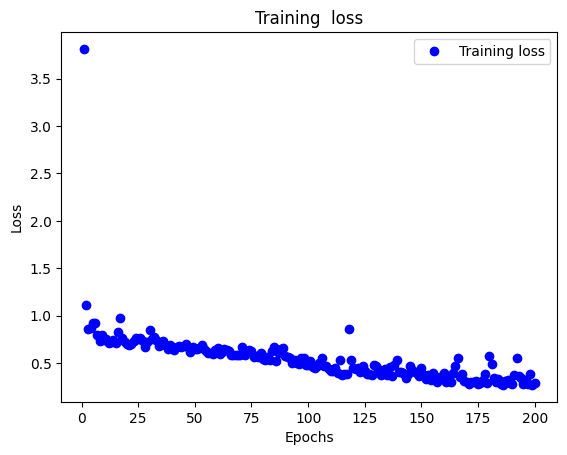

In [55]:
epochs=range(1,len(loss)+1)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.plot(epochs, loss, 'bo', label='Training loss')
plt.title('Training  loss')
plt.legend()
plt.show()

**ניתן לראות מהגרף שככל שמספר החיזויים גדל כך כמות הטעויות יורדת**

**ניתן ראות גם כי הגרף כמעט הופכי ביחס לגרף הדיוק**

**השוואה**

ההבדל בין שתי שיטות הסיווג הן כאלה

עובד בשיטה בה הוא מציב גבול בעזרת נתון מסוים ואז הוא בודק בעזרת מספר הנתונים שקרובים אליו (אפשר לשנות) לאיזה קטגוריית סיווג הוא משתייך KNN

עובדת על ידי חיבור של שכבות נוירונים ושימוש בגרפים ככל שיהיו יותר שכבות וגרפים מתאימים החיזוי יהיה גבוה יותר עד שנגיע ללמידת יתר ANN

# **סיכום ורפלקציה**

מסקנות

בפרויקט בדקתי את הקשר בין כמות הקלוריות שמתאמן שורף במהלך אימון לבין נתונים שונים כמו נתוני הגוף שלו, סוג האימון וזמן האימון. במהלך העבודה ביצעתי עיבוד לנתונים, כולל התאמות לקטגוריות שונות והמרה של משתנים מסוימים כדי שיהיה ניתן להשתמש בהם לניתוח ולבניית מודלים. בנוסף יצרתי גרפים שונים כדי להבין טוב יותר את הקשרים בין המשתנים.

מהניתוח ניתן לראות כי קיימים מספר גורמים משמעותיים שמשפיעים על כמות הקלוריות שנשרפות במהלך אימון. לדוגמה, משך זמן האימון וקצב הלב במהלך האימון משפיעים באופן ישיר על כמות הקלוריות שנשרפת, מכיוון שככל שהאימון ארוך ואינטנסיבי יותר הגוף שורף יותר אנרגיה. גם סוג האימון משחק תפקיד, כאשר אימונים בעצימות גבוהה כמו אימוני HIIT או אירובי נוטים לגרום לשריפת קלוריות גבוהה יותר לעומת אימונים רגועים יותר.

בנוסף לכך ביצעתי חיזוי של כמות הקלוריות באמצעות שתי שיטות למידת מכונה: KNN ו-ANN. לאחר השוואה בין התוצאות ראיתי כי המודל ANN נתן תוצאות טובות יותר בהשוואה ל-KNN, עם שיפור של בערך 0.1 במדד הביצועים. פער זה מצביע על כך שמודל של רשת נוירונים מתאים יותר לנתונים שבמסד הנתונים שלי ויכול לזהות טוב יותר את הקשרים המורכבים בין המשתנים.

לסיכום ניתן לומר כי שילוב של ניתוח נתונים, גרפים ושימוש במודלים של למידת מכונה מאפשר להבין טוב יותר מהם הגורמים שמשפיעים על שריפת קלוריות במהלך אימון, וכן לבצע חיזוי מדויק יותר של התוצאה.
רפלקציה אישית

במהלך העבודה על הפרויקט למדתי כיצד לעבוד עם נתונים בצורה מסודרת ולנתח אותם באמצעות Python ו-Google Colab. למדתי כיצד לטעון קובץ נתונים, להבין את המשמעות של כל עמודה, לבצע עיבוד נתונים וליצור גרפים שמציגים בצורה ויזואלית את המידע.

אחד האתגרים בתהליך היה להבין כיצד להכין את הנתונים לניתוח, למשל להמיר נתונים קטגוריאליים כמו מין או סוג אימון לערכים מספריים כדי שניתן יהיה להשתמש בהם בניתוח. בנוסף היה צריך להבין אילו משתנים יכולים להשפיע באמת על שריפת הקלוריות ואילו פחות רלוונטיים לשאלת המחקר.

נושא שמצאתי מעניין במיוחד היה הקשר בין עצימות האימון, קצב הלב ושריפת הקלוריות. דרך הניתוח היה אפשר לראות בצורה ברורה כיצד פעילות גופנית בעצימות גבוהה יותר גורמת להוצאה אנרגטית גדולה יותר.

בנוסף העמקתי באופן עצמאי בנושאים כמו שימוש בספריות Python לניתוח נתונים ויצירת גרפים, דבר שעזר לי להבין טוב יותר כיצד ניתן להשתמש בנתונים כדי להסיק מסקנות.

בסיכום הפרויקט אני מרגיש שהעבודה תרמה להבנה שלי בתחום ניתוח הנתונים וליכולת שלי לעבוד עם נתונים אמיתיים, להסיק מהם מסקנות ולהציג אותם בצורה ברורה.